# 07 — Feature Importance (Mục 4.6)

**Mục tiêu:** xác định biến nào ảnh hưởng mạnh nhất đến xác suất khách hàng rời bỏ (churn) và theo chiều nào, làm căn cứ cho phần insight (Chương 5) và đề xuất tính năng cảnh báo trong CRM (Chương 6).

**Input:** `data/processed/customer_features_labeled.csv` + mô hình đã chốt ở `05_model_training.ipynb` — **Logistic Regression, ngưỡng 0,35** (F1 cao nhất trên validation, test ROC-AUC 0,768).
**Output:** `reports/figures/feature_importance.png`, `reports/figures/feature_effect_churn_rate.png`, `reports/feature_importance_table.csv`.

**Phương pháp — 3 lớp bằng chứng:**
1. **Hệ số chuẩn hóa của Logistic Regression** → cho biết *chiều* tác động (tăng/giảm nguy cơ churn) và độ lớn trên 1 độ lệch chuẩn; quy đổi ra odds ratio theo đơn vị dễ hiểu.
2. **Permutation importance** trên tập **test** (xáo trộn từng biến 50 lần, đo mức giảm ROC-AUC) → đo mức đóng góp *thực tế* vào khả năng dự báo, không phụ thuộc thang đo.
3. **Đối chiếu với RF_3 và XGB_2** (cấu hình tốt nhất ở 05) → kiểm tra thứ hạng có ổn định giữa các mô hình không. Bổ sung **group permutation** cho nhóm biến khối lượng mua (Frequency, Monetary, TotalItems, UniqueProducts) vì các biến này tương quan rất cao với nhau.

> Ghi chú: nhãn `is_churn` là nhãn **tương lai** (không mua trong [01/06/2011, 28/11/2011)), không suy ra từ Recency, nên Recency được phép làm biến đầu vào mà không gây leakage.

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

ROOT = Path('..')
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
NAVY, ORANGE, GREY = '#274b73', '#b5622b', '#9aa3ad'   # cùng bảng màu với các hình Chương 4
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9})
SEED = 42

In [2]:
df = pd.read_csv(ROOT / 'data/processed/customer_features_labeled.csv')
feature_cols = ['Recency', 'Frequency', 'Monetary', 'AvgOrderValue', 'UniqueProducts', 'TotalItems']
X, y = df[feature_cols], df['is_churn']

# Chia dữ liệu GIỐNG HỆT 05_model_training: 60% train / 20% validation / 20% test
X_tv, X_test, y_tv, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_tv, y_tv, test_size=0.25, random_state=SEED, stratify=y_tv)
print('Train/Val/Test:', len(X_train), len(X_val), len(X_test), '| tỷ lệ churn:', round(y.mean(), 4))

Train/Val/Test: 1594 532 532 | tỷ lệ churn: 0.3025


In [3]:
# Mô hình đã chọn: Logistic Regression (ngưỡng 0,35). Ưu tiên nạp file .pkl từ 05; nếu chưa có thì huấn luyện lại đúng cấu hình.
model_path, scaler_path = ROOT / 'models/logistic_churn_model.pkl', ROOT / 'models/scaler.pkl'
if model_path.exists() and scaler_path.exists():
    lr, scaler = joblib.load(model_path), joblib.load(scaler_path)
    print('Đã nạp model từ models/')
else:
    scaler = StandardScaler().fit(X_train)
    lr = LogisticRegression(max_iter=1000, random_state=SEED).fit(scaler.transform(X_train), y_train)
    print('Chưa có models/*.pkl trên repo -> huấn luyện lại đúng cấu hình của 05')
lr_pipe = make_pipeline(scaler, lr)
THRESHOLD = 0.35

# Kiểm tra tái lập: test ROC-AUC phải = 0,7679 như 05
print('Test ROC-AUC (LR):', round(roc_auc_score(y_test, lr_pipe.predict_proba(X_test)[:, 1]), 4))

# 2 mô hình đối chứng: cấu hình tốt nhất ở 05
rf = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=4, class_weight='balanced',
                            random_state=SEED, n_jobs=-1).fit(X_train, y_train)
xgb = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.03, random_state=SEED,
                    eval_metric='logloss').fit(X_train, y_train)
for n, m in [('RF_3', rf), ('XGB_2', xgb)]:
    print(f'Test ROC-AUC ({n}):', round(roc_auc_score(y_test, m.predict_proba(X_test)[:, 1]), 4))

Chưa có models/*.pkl trên repo -> huấn luyện lại đúng cấu hình của 05
Test ROC-AUC (LR): 0.7679


Test ROC-AUC (RF_3): 0.7773
Test ROC-AUC (XGB_2): 0.7662


## 1. Hệ số chuẩn hóa & odds ratio (Logistic Regression)
Hệ số β là thay đổi log-odds churn khi biến tăng **1 độ lệch chuẩn** (SD tính trên tập train). β > 0: tăng nguy cơ churn; β < 0: giảm nguy cơ. Để dễ diễn giải cho nghiệp vụ, quy đổi sang odds ratio theo một đơn vị thực tế: OR = exp(β / SD × Δ).

In [4]:
units = {'Recency': (30, '+30 ngày không mua'), 'Frequency': (1, '+1 hóa đơn'),
         'Monetary': (1000, '+1.000 GBP chi tiêu'), 'AvgOrderValue': (100, '+100 GBP/đơn'),
         'UniqueProducts': (10, '+10 mã sản phẩm khác nhau'), 'TotalItems': (1000, '+1.000 sản phẩm')}
coef = pd.DataFrame({'Feature': feature_cols, 'Coef_std': lr.coef_[0], 'SD_train': scaler.scale_})
coef['OR_per_SD'] = np.exp(coef['Coef_std'])
coef['Don_vi'] = coef['Feature'].map(lambda f: units[f][1])
coef['OR_per_unit'] = np.exp(coef['Coef_std'] / coef['SD_train'] * coef['Feature'].map(lambda f: units[f][0]))
coef['Chieu'] = np.where(coef['Coef_std'] > 0, 'Tăng nguy cơ churn', 'Giảm nguy cơ churn')
coef.sort_values('Coef_std', key=abs, ascending=False).round(4)

,Feature,Coef_std,SD_train,OR_per_SD,Don_vi,OR_per_unit,Chieu
1,Frequency,-2.2489,9.7020,0.1055,+1 hóa đơn,0.7931,Giảm nguy cơ churn
5,TotalItems,-1.1999,6101.6082,0.3012,+1.000 sản phẩm,0.8215,Giảm nguy cơ churn
4,UniqueProducts,-0.6298,96.7895,0.5327,+10 mã sản phẩm khác nhau,0.9370,Giảm nguy cơ churn
0,Recency,0.3317,50.0467,1.3933,+30 ngày không mua,1.2200,Tăng nguy cơ churn
2,Monetary,-0.1531,9235.5164,0.8581,+1.000 GBP chi tiêu,0.9836,Giảm nguy cơ churn
3,AvgOrderValue,0.0183,355.7004,1.0185,+100 GBP/đơn,1.0052,Tăng nguy cơ churn


## 2. Permutation importance trên tập test (ΔROC-AUC)
Xáo trộn ngẫu nhiên giá trị của một biến (50 lần) rồi đo ROC-AUC giảm bao nhiêu. Giảm càng nhiều → mô hình càng dựa vào biến đó. Chạy cho cả 3 mô hình để kiểm tra độ ổn định.

In [5]:
perm = {}
for name, m in [('Logistic Regression', lr_pipe), ('Random Forest (RF_3)', rf), ('XGBoost (XGB_2)', xgb)]:
    r = permutation_importance(m, X_test, y_test, scoring='roc_auc', n_repeats=50, random_state=SEED, n_jobs=-1)
    perm[name] = pd.DataFrame({'mean': r.importances_mean, 'std': r.importances_std}, index=feature_cols)

perm_mean = pd.DataFrame({k: v['mean'] for k, v in perm.items()})
rank = perm_mean.rank(ascending=False).astype(int).add_suffix(' (hạng)')
pd.concat([perm_mean.round(4), rank], axis=1).sort_values('Logistic Regression', ascending=False)

,Logistic Regression,Random Forest (RF_3),XGBoost (XGB_2),Logistic Regression (hạng),Random Forest (RF_3) (hạng),XGBoost (XGB_2) (hạng)
Frequency,0.1145,0.0269,0.0399,1,2,2
UniqueProducts,0.0351,0.0147,0.0258,2,4,4
Recency,0.0234,0.0244,0.0280,3,3,3
TotalItems,0.0189,0.0310,0.0502,4,1,1
Monetary,0.0007,0.0095,-0.0022,5,5,5
AvgOrderValue,0.0006,-0.0010,-0.0036,6,6,6


## 3. Group permutation — xử lý đa cộng tuyến
Frequency, Monetary, TotalItems, UniqueProducts tương quan Spearman 0,68–0,95 với nhau. Khi một biến bị xáo trộn, các biến còn lại vẫn "gánh" thông tin, nên importance của từng biến riêng lẻ (nhất là Monetary) bị đánh giá thấp. Xáo trộn **cả nhóm cùng lúc** để đo đóng góp thật của khía cạnh "khối lượng/mức độ gắn bó mua hàng".

In [6]:
print(df[feature_cols].corr(method='spearman').round(2))

def group_perm(model, X_, y_, cols, n=50, seed=SEED):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y_, model.predict_proba(X_)[:, 1]); drops = []
    for _ in range(n):
        Xp = X_.copy(); idx = rng.permutation(len(Xp))
        Xp[cols] = Xp[cols].values[idx]          # cùng 1 hoán vị cho cả nhóm -> giữ quan hệ nội bộ nhóm
        drops.append(base - roc_auc_score(y_, model.predict_proba(Xp)[:, 1]))
    return base, np.mean(drops), np.std(drops)

groups = {'Nhóm khối lượng mua (Frequency, Monetary, TotalItems, UniqueProducts)':
              ['Frequency', 'Monetary', 'TotalItems', 'UniqueProducts'],
          'Recency': ['Recency'], 'AvgOrderValue': ['AvgOrderValue']}
rows = []
for g, cols in groups.items():
    base, mu, sd = group_perm(lr_pipe, X_test, y_test, cols)
    rows.append({'Nhóm biến': g, 'AUC gốc': base, 'ΔAUC khi xáo trộn': mu, 'std': sd, 'AUC còn lại': base - mu})
group_df = pd.DataFrame(rows); group_df.round(4)

                Recency  Frequency  Monetary  AvgOrderValue  UniqueProducts  \
Recency            1.00      -0.38     -0.35          -0.12           -0.25   
Frequency         -0.38       1.00      0.84           0.18            0.68   
Monetary          -0.35       0.84      1.00           0.65            0.73   
AvgOrderValue     -0.12       0.18      0.65           1.00            0.39   
UniqueProducts    -0.25       0.68      0.73           0.39            1.00   
TotalItems        -0.34       0.80      0.95           0.61            0.72   

                TotalItems  
Recency              -0.34  
Frequency             0.80  
Monetary              0.95  
AvgOrderValue         0.61  
UniqueProducts        0.72  
TotalItems            1.00  


,Nhóm biến,AUC gốc,ΔAUC khi xáo trộn,std,AUC còn lại
0,"Nhóm khối lượng mua (Frequency, Monetary, Tota...",0.7679,0.2250,0.0233,0.5429
1,Recency,0.7679,0.0234,0.0076,0.7445
2,AvgOrderValue,0.7679,0.0006,0.0007,0.7673


## 4. Chiều tác động thực tế — tỷ lệ churn theo nhóm ngũ phân vị
Kiểm tra trên dữ liệu thô (toàn bộ 2.658 khách) xem chiều tác động có khớp với dấu hệ số không. Frequency và Monetary đã có ở Hình 4.7 (mục 4.3) nên ở đây trình bày Recency, TotalItems, UniqueProducts, AvgOrderValue.

In [7]:
eff_cols = ['Recency', 'TotalItems', 'UniqueProducts', 'AvgOrderValue']
eff = {}
for c in eff_cols:
    q = pd.qcut(df[c].rank(method='first'), 5, labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
    g = df.groupby(q, observed=True).agg(churn=('is_churn', 'mean'), lo=(c, 'min'), hi=(c, 'max'), n=(c, 'size'))
    eff[c] = g
    print(c); print(g.assign(churn=lambda t: (t.churn * 100).round(1)), '\n')

Recency
         churn   lo   hi    n
Recency                      
Q1        15.6    1   15  532
Q2        17.9   15   34  531
Q3        29.7   34   64  532
Q4        39.9   64  106  531
Q5        48.1  106  180  532 

TotalItems
            churn    lo      hi    n
TotalItems                          
Q1           58.1     0     183  532
Q2           45.2   183     393  531
Q3           27.4   393     777  532
Q4           14.1   778    1566  531
Q5            6.4  1567  176140  532 

UniqueProducts
                churn   lo    hi    n
UniqueProducts                       
Q1               50.6    1    17  532
Q2               45.2   17    36  531
Q3               29.1   36    65  532
Q4               16.4   65   116  531
Q5               10.0  116  1601  532 

AvgOrderValue
               churn          lo           hi    n
AvgOrderValue                                     
Q1              47.6   -6.100000   166.410000  532
Q2              31.1  166.500000   248.710000  531
Q3     

## 5. Biểu đồ & bảng xuất ra báo cáo

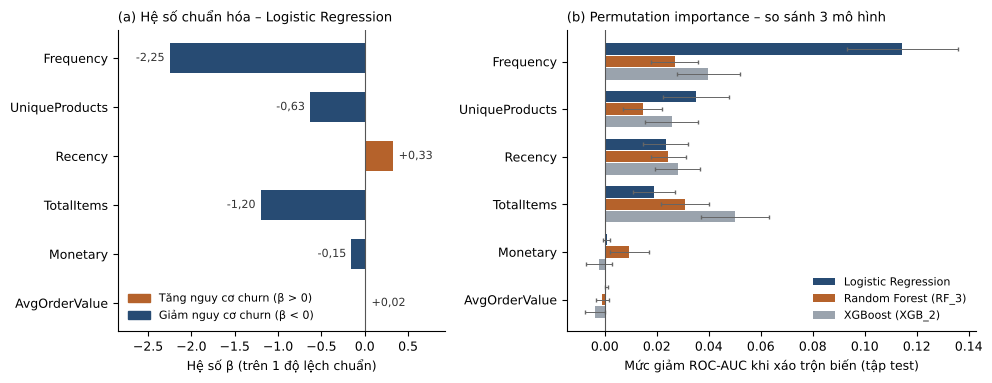

In [8]:
order = perm_mean['Logistic Regression'].sort_values().index.tolist()   # sắp theo importance của mô hình đã chọn
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.9), gridspec_kw={'width_ratios': [1, 1.25]})

# (a) Hệ số chuẩn hóa — màu theo chiều tác động
cs = coef.set_index('Feature').loc[order, 'Coef_std']
a1.barh(order, cs, color=[ORANGE if v > 0 else NAVY for v in cs], height=0.6)
a1.axvline(0, color='#555', lw=0.8)
for i, v in enumerate(cs):
    a1.text(v + (0.06 if v >= 0 else -0.06), i, f'{v:+.2f}'.replace('.', ','), va='center',
            ha='left' if v >= 0 else 'right', fontsize=8, color='#333')
a1.set_xlim(cs.min() - 0.6, max(cs.max(), 0) + 0.6)
a1.set_xlabel('Hệ số β (trên 1 độ lệch chuẩn)')
a1.set_title('(a) Hệ số chuẩn hóa – Logistic Regression', fontsize=9.5, loc='left')
from matplotlib.patches import Patch
a1.legend(handles=[Patch(color=ORANGE, label='Tăng nguy cơ churn (β > 0)'), Patch(color=NAVY, label='Giảm nguy cơ churn (β < 0)')],
          frameon=False, fontsize=8, loc='lower left')

# (b) Permutation importance — 3 mô hình
h = 0.26; yy = np.arange(len(order))
for k, (name, col) in enumerate(zip(perm, [NAVY, ORANGE, GREY])):
    p = perm[name].loc[order]
    a2.barh(yy + (1 - k) * h, p['mean'], h * 0.92, xerr=p['std'], color=col, label=name,
            error_kw=dict(lw=0.7, capsize=1.5, ecolor='#666'))
a2.set_yticks(yy); a2.set_yticklabels(order); a2.axvline(0, color='#555', lw=0.8)
a2.set_xlabel('Mức giảm ROC-AUC khi xáo trộn biến (tập test)')
a2.set_title('(b) Permutation importance – so sánh 3 mô hình', fontsize=9.5, loc='left')
a2.legend(frameon=False, fontsize=8, loc='lower right')
for a in (a1, a2):
    a.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / 'feature_importance.png', dpi=200, bbox_inches='tight'); plt.show()

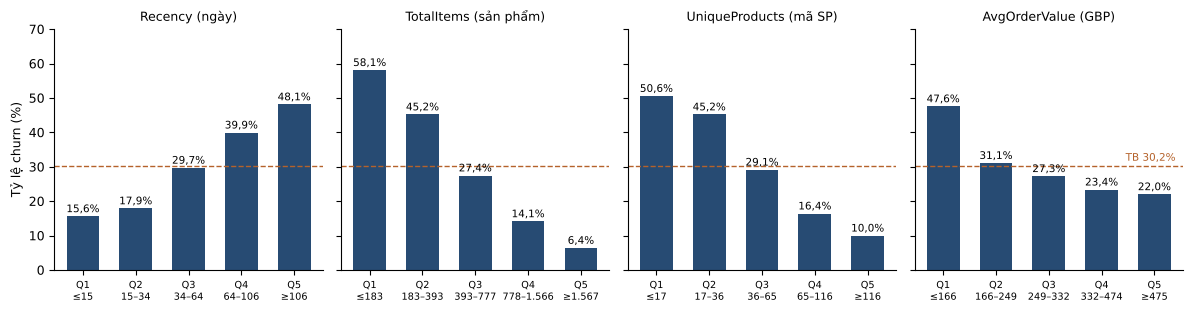

In [9]:
fmt = lambda v: f'{v:,.0f}'.replace(',', '.')
fig, axs = plt.subplots(1, 4, figsize=(12, 3.2), sharey=True)
overall = df['is_churn'].mean() * 100
titles = {'Recency': 'Recency (ngày)', 'TotalItems': 'TotalItems (sản phẩm)',
          'UniqueProducts': 'UniqueProducts (mã SP)', 'AvgOrderValue': 'AvgOrderValue (GBP)'}
for a, c in zip(axs, eff_cols):
    g = eff[c]; v = g['churn'] * 100
    a.bar(range(5), v, color=NAVY, width=0.62)
    a.axhline(overall, color=ORANGE, ls='--', lw=1)
    for i, val in enumerate(v):
        a.text(i, val + 1.2, f'{val:.1f}%'.replace('.', ','), ha='center', fontsize=7.5)
    a.set_xticks(range(5))
    labs = [f'Q{i+1}\n' + ('≤' + fmt(hi) if i == 0 else '≥' + fmt(lo) if i == 4 else f'{fmt(lo)}–{fmt(hi)}')
            for i, (lo, hi) in enumerate(zip(g['lo'], g['hi']))]
    a.set_xticklabels(labs, fontsize=7)
    a.set_title(titles[c], fontsize=9); a.spines[['top', 'right']].set_visible(False)
axs[0].set_ylabel('Tỷ lệ churn (%)'); axs[0].set_ylim(0, 70)
axs[-1].text(4.4, overall + 1.5, f'TB {overall:.1f}%'.replace('.', ','), color=ORANGE, fontsize=7.5, ha='right')
plt.tight_layout()
plt.savefig(FIG / 'feature_effect_churn_rate.png', dpi=200, bbox_inches='tight'); plt.show()

In [10]:
table = (coef.set_index('Feature')[['Coef_std', 'OR_per_SD', 'Don_vi', 'OR_per_unit', 'Chieu']]
         .join(perm_mean.add_prefix('PermAUC_'))
         .join(rank)
         .sort_values('PermAUC_Logistic Regression', ascending=False))
table.round(4).to_csv(ROOT / 'reports/feature_importance_table.csv', encoding='utf-8-sig')
group_df.round(4).to_csv(ROOT / 'reports/feature_importance_group.csv', index=False, encoding='utf-8-sig')
table.round(4)

,Coef_std,OR_per_SD,Don_vi,OR_per_unit,Chieu,PermAUC_Logistic Regression,PermAUC_Random Forest (RF_3),PermAUC_XGBoost (XGB_2),Logistic Regression (hạng),Random Forest (RF_3) (hạng),XGBoost (XGB_2) (hạng)
Feature,,,,,,,,,,,
Frequency,-2.2489,0.1055,+1 hóa đơn,0.7931,Giảm nguy cơ churn,0.1145,0.0269,0.0399,1,2,2
UniqueProducts,-0.6298,0.5327,+10 mã sản phẩm khác nhau,0.9370,Giảm nguy cơ churn,0.0351,0.0147,0.0258,2,4,4
Recency,0.3317,1.3933,+30 ngày không mua,1.2200,Tăng nguy cơ churn,0.0234,0.0244,0.0280,3,3,3
TotalItems,-1.1999,0.3012,+1.000 sản phẩm,0.8215,Giảm nguy cơ churn,0.0189,0.0310,0.0502,4,1,1
Monetary,-0.1531,0.8581,+1.000 GBP chi tiêu,0.9836,Giảm nguy cơ churn,0.0007,0.0095,-0.0022,5,5,5
AvgOrderValue,0.0183,1.0185,+100 GBP/đơn,1.0052,Tăng nguy cơ churn,0.0006,-0.0010,-0.0036,6,6,6


## 6. Kết luận ngắn (chi tiết diễn giải trong báo cáo mục 4.6)
- **Frequency** là yếu tố quan trọng nhất, nhất quán ở cả 3 mô hình: khách càng mua nhiều lần trước thời điểm dự báo càng ít khả năng rời bỏ.
- **Recency** và **UniqueProducts**, **TotalItems** là nhóm quan trọng tiếp theo: lâu không mua → nguy cơ churn tăng; mua đa dạng, nhiều sản phẩm → gắn bó hơn.
- **Monetary** và **AvgOrderValue** gần như không đóng góp thêm khi đã biết các biến trên — giá trị tiền không phải động lực chính của churn; thông tin của Monetary đã nằm trong Frequency/TotalItems (đa cộng tuyến).
- Hàm ý CRM: cảnh báo churn nên dựa trên **mức độ gắn bó (tần suất, độ rộng giỏ hàng) + thời gian im lặng**, không chỉ dựa trên doanh thu của khách.